# Backtesting the VaR of the book

Every 1-day VaR 99% of [`03_var`](03_var.ipynb) is compared with the book's actual P&L on the day it covers, from 2 January 2012 to 20 October 2026 (gold tables `fact_backtest` and `fact_backtest_summary`, produced by [`pipeline/backtest.py`](../pipeline/backtest.py)).

**Exception:** a day whose loss exceeds the VaR computed at the previous close; a correct 99% VaR is exceeded on 1% of days.
- **Kupiec (1995):** is the exception rate consistent with 1%? Too many and too few both fail.
- **Christoffersen (1998):** are exceptions independent, or does one make the next more likely? Clusters reveal a VaR that adapts too slowly. The conditional coverage test combines both.
- **Basel traffic light** (Basel Committee, 1996): exceptions over the last 250 days; green 0–4, yellow 5–9, red 10 or more.

The tests run on the whole period and on the two stress years, 2020 and 2022. The P&L is hypothetical: constant positions revalued with market moves.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "requirements.txt").exists())
GOLD = ROOT / "data" / "gold"
INK, INK2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e6e5e1", "#fcfcfb"
METHOD_COLORS = {"hs": "#a9a8a3", "param_ewma": "#1baf7a", "param_champion": "#2a78d6", "fhs": "#eb6834"}
METHOD_NAMES = {
    "hs": "Historical simulation",
    "param_ewma": "Parametric (EWMA)",
    "param_garch": "Parametric (GARCH)",
    "param_champion": "Parametric (GJR)",
    "fhs": "Filtered historical simulation",
}
ZONE_COLORS = {"green": "#e3f1e3", "yellow": "#fbf0d2", "red": "#f6dcd9"}
plt.rcParams.update(
    {
        "figure.figsize": (9, 3.6),
        "figure.dpi": 110,
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "axes.edgecolor": GRID,
        "axes.labelcolor": INK2,
        "axes.titlecolor": INK,
        "axes.titlesize": 11,
        "axes.titleweight": "bold",
        "axes.titlelocation": "left",
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.color": GRID,
        "grid.linewidth": 0.6,
        "xtick.color": INK2,
        "ytick.color": INK2,
        "lines.linewidth": 1.5,
        "legend.frameon": False,
        "font.size": 9,
    }
)

daily = pd.read_parquet(GOLD / "fact_backtest.parquet").assign(
    for_date=lambda d: pd.to_datetime(d["for_date"])
)
summary = pd.read_parquet(GOLD / "fact_backtest_summary.parquet")
whole = summary.loc[summary["period"].str.contains("-"), "period"].iloc[0]
columns = [
    "n_days",
    "n_exceptions",
    "expected_exceptions",
    "kupiec_p",
    "christoffersen_p",
    "conditional_coverage_p",
    "worst_zone",
    "zone_at_end",
]


def by_method(period: str) -> pd.DataFrame:
    part = summary[summary["period"] == period].set_index("method_id").reindex(list(METHOD_NAMES))
    return part[columns].rename(index=METHOD_NAMES).round(3)


print(
    f"{daily['for_date'].nunique()} days, {daily['for_date'].min():%d %b %Y} to {daily['for_date'].max():%d %b %Y}; whole period: {whole}"
)

3823 days, 02 Jan 2012 to 20 Oct 2026; whole period: 2012-2026


## 1. The whole period

In [2]:
by_method(whole)

,n_days,n_exceptions,expected_exceptions,kupiec_p,christoffersen_p,conditional_coverage_p,worst_zone,zone_at_end
method_id,,,,,,,,
Historical simulation,3823,55,38.23,0.011,0.000,0.000,red,green
Parametric (EWMA),3823,74,38.23,0.000,0.003,0.000,red,green
Parametric (GARCH),3823,56,38.23,0.007,0.010,0.001,red,green
Parametric (GJR),3823,54,38.23,0.016,0.213,0.025,yellow,green
Filtered historical simulation,3823,38,38.23,0.970,0.382,0.682,yellow,green


Filtered historical simulation is the only method that passes every test: 38 exceptions for 38.2 expected (Kupiec p = 0.970), no clustering (Christoffersen p = 0.382). Every normal parametric method has too many exceptions (54 to 74; Kupiec p ≤ 0.016): with the right volatility but normal tails, a 99% VaR is exceeded about 1.4 times more often than promised (54 for GJR), consistent with the kurtosis of about 10 measured in [`00_stylized_facts`](00_stylized_facts.ipynb). Historical simulation has both faults: too many exceptions (55) and exceptions in clusters (Christoffersen p < 0.001).

## 2. The Basel traffic light over time

zone,green,yellow,red
method_id,,,
Historical simulation,0.672,0.273,0.055
Parametric (EWMA),0.494,0.463,0.043
Parametric (GARCH),0.743,0.249,0.008
Parametric (GJR),0.706,0.294,0.000
Filtered historical simulation,0.932,0.068,0.000


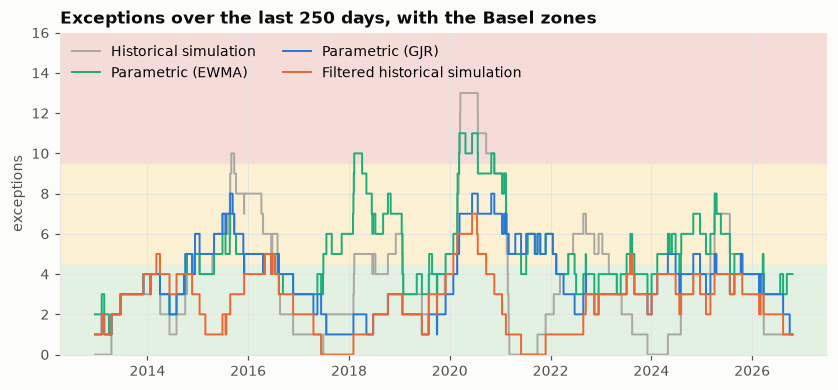

In [3]:
counts = daily.pivot(index="for_date", columns="method_id", values="exceptions_250d").astype(float)
fig, ax = plt.subplots(figsize=(9, 3.8))
for low, high, name in [(0, 4.5, "green"), (4.5, 9.5, "yellow"), (9.5, 16, "red")]:
    ax.axhspan(low, high, color=ZONE_COLORS[name], zorder=0)
for method in ["hs", "param_ewma", "param_champion", "fhs"]:
    ax.step(
        counts.index,
        counts[method],
        where="post",
        color=METHOD_COLORS[method],
        linewidth=1.3,
        label=METHOD_NAMES[method],
    )
ax.set(title="Exceptions over the last 250 days, with the Basel zones", ylabel="exceptions", ylim=(0, 16))
ax.legend(loc="upper left", ncols=2)
shares = (
    daily.dropna(subset=["zone"])
    .groupby("method_id")["zone"]
    .value_counts(normalize=True)
    .unstack(fill_value=0.0)
)
shares.reindex(index=list(METHOD_NAMES), columns=["green", "yellow", "red"]).rename(index=METHOD_NAMES).round(
    3
)

Filtered historical simulation spends 93.2% of the days in the green zone and never reaches red; historical simulation reaches red on 5.5% of the days, EWMA on 4.3%. The zone is the one a supervisor would apply, with a capital add-on from yellow and a presumption against the model in red.

## 3. Stress years

In [4]:
fhs = daily[daily["method_id"] == "fhs"]
print(
    "Filtered historical simulation, exceptions by year:",
    fhs.groupby(fhs["for_date"].dt.year)["is_exception"].sum().to_dict(),
)
pd.concat({"2020": by_method("2020"), "2022": by_method("2022")})[
    ["n_exceptions", "expected_exceptions", "kupiec_p", "christoffersen_p", "zone_at_end"]
]

Filtered historical simulation, exceptions by year: {2012: 1, 2013: 4, 2014: 3, 2015: 4, 2016: 2, 2017: 0, 2018: 3, 2019: 4, 2020: 3, 2021: 1, 2022: 3, 2023: 2, 2024: 4, 2025: 3, 2026: 1}


n_exceptions  expected_exceptions  \
     method_id                                                           
2020 Historical simulation                      9                 2.59   
     Parametric (EWMA)                          9                 2.59   
     Parametric (GARCH)                         8                 2.59   
     Parametric (GJR)                           7                 2.59   
     Filtered historical simulation             3                 2.59   
2022 Historical simulation                      6                 2.58   
     Parametric (EWMA)                          4                 2.58   
     Parametric (GARCH)                         4                 2.58   
     Parametric (GJR)                           3                 2.58   
     Filtered historical simulation             3                 2.58   

                                     kupiec_p  christoffersen_p zone_at_end  
     method_id                                                               
2020 Historical simulation              0.002             0.002      yellow  
     Parametric (EWMA)                  0.002             0.304      yellow  
     Parametric (GARCH)                 0.007             0.474      yellow  
     Parametric (GJR)                   0.023             0.532      yellow  
     Filtered historical simulation     0.803             0.790       green  
2022 Historical simulation              0.068             0.592      yellow  
     Parametric (EWMA)                  0.411             0.722       green  
     Parametric (GARCH)                 0.411             0.722       green  
     Parametric (GJR)                   0.798             0.790       green  
     Filtered historical simulation     0.798             0.790       green

In 2020 only filtered historical simulation passes (3 exceptions for 2.6 expected, Kupiec p = 0.803); the other methods have 7 to 9 and are rejected. In 2022, a year of steady rather than sudden stress, every method passes Kupiec at 5%, historical simulation narrowly (6 exceptions, p = 0.068). Filtered historical simulation has 0 to 4 exceptions in every calendar year.

## 4. Which GJR forecast for a parametric VaR?

In [5]:
import sys

sys.path.insert(0, str(ROOT))
from pipeline import backtest, var  # noqa: E402 - the pipeline's own tests and VaR formulas

forecasts = pd.read_parquet(GOLD / "fact_forecast.parquet").assign(date=lambda d: pd.to_datetime(d["date"]))
five_day = forecasts[(forecasts["series_id"] == "book") & (forecasts["model_id"] == "gjr")].set_index("date")[
    "forecast_var"
]
one_day = daily[daily["method_id"] == "param_champion"].set_index("for_date")
calendar = one_day.index.union(five_day.index)
five_day_var = var.to_for_date(var.parametric(five_day), calendar)["var"].reindex(one_day.index).dropna()
days = five_day_var.index
rows = {}
for label, value_at_risk in [
    ("1-day forecast", one_day.loc[days, "var_99_eur"]),
    ("5-day average", five_day_var),
]:
    flags = (one_day.loc[days, "pnl_eur"] < -value_at_risk).to_numpy()
    rows[label] = {
        "days": len(flags),
        "exceptions": int(flags.sum()),
        "expected": round(len(flags) * backtest.EXCEPTION_RATE, 1),
        "kupiec_p": round(backtest.kupiec(flags)[1], 3),
        "christoffersen_p": round(backtest.christoffersen(flags)[1], 3),
        "exceptions in 2020": int(flags[days.year == 2020].sum()),
    }
pd.DataFrame.from_dict(rows, orient="index")

,days,exceptions,expected,kupiec_p,christoffersen_p,exceptions in 2020
1-day forecast,2273,34,22.7,0.027,0.309,7
5-day average,2273,29,22.7,0.205,0.387,7


The 5-day average gives fewer exceptions (29 against 34 for 22.7 expected) and passes Kupiec where the 1-day forecast does not (p = 0.205 against 0.027); in 2020 both have 7. The gain comes from calm periods: GJR forecasts revert to a long-run level, so the 5-day average sits above tomorrow's forecast when volatility is low and cushions the sudden jumps out of quiet markets. It does not rescue the normal method, which still has more exceptions than expected, and filtered historical simulation, which uses the 1-day forecast, already passes.

## 5. Conclusions and consequences

| Finding | Consequence |
|---|---|
| Filtered historical simulation: 38 exceptions for 38.2 expected, independent, 3 in 2020 and 3 in 2022, never in the red zone | Recommended risk figure for the book |
| Normal parametric methods: too many exceptions over the whole period and in 2020 | Kept as benchmarks; normal tails understate the 99% loss |
| Historical simulation: too many exceptions, clustered, red zone after 2020 | Benchmark only; its reaction depends on the window, not on current risk |
| The 5-day GJR average backtests better than the 1-day forecast for a normal VaR | The volatility input matters less than the tail model; recorded, no change to the recommendation |

**Limits.** One book with constant positions and hypothetical P&L (no intraday trading, fees or carry); 38 expected exceptions give the tests limited power to separate close methods; ES is not backtested directly (under FRTB, desks are backtested on VaR at 97.5% and 99%).

## References

- Barone-Adesi, G., Giannopoulos, K., & Vosper, L. (1999). VaR without correlations for portfolios of derivative securities. *Journal of Futures Markets*, 19(5), 583–602.
- Basel Committee on Banking Supervision (1996). *Supervisory framework for the use of "backtesting" in conjunction with the internal models approach to market risk capital requirements*. Bank for International Settlements.
- Basel Committee on Banking Supervision (2019). *Minimum capital requirements for market risk*. Bank for International Settlements.
- Christoffersen, P. F. (1998). Evaluating interval forecasts. *International Economic Review*, 39(4), 841–862.
- Kupiec, P. H. (1995). Techniques for verifying the accuracy of risk measurement models. *Journal of Derivatives*, 3(2), 73–84.
- Pritsker, M. (2006). The hidden dangers of historical simulation. *Journal of Banking & Finance*, 30(2), 561–582.